# **Exploratory Data Analysis**
## Give Me Some Credit

The table is the Kaggle Give Me Some Credit file: one row per applicant, a binary label for serious delinquency within two years, and ten fields from the application and the credit file. We look at the shape of each field, at the values that are hard to trust, and at the missing entries.

### Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

### Data loading and verification

The raw file is `cs-training.csv`. Its first column is an applicant identifier, so we take that column as the index and keep the eleven data columns. We check the shape and the first rows, then cut the file once into a pool and a test set. The two pieces are written to `pool.csv` and `test.csv`. That split is the one the rest of the study uses, so everything below is a reading of the pool the models will actually see.

In [2]:
df = pd.read_csv('../data/raw/cs-training.csv', index_col=0)

df.shape

(150000, 11)

In [3]:
df.head()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [20]:
pool, test = train_test_split(
    df, test_size=30_000, stratify=df["SeriousDlqin2yrs"], random_state=42,
)

pool.to_csv("../data/pool.csv", index=False)
test.to_csv("../data/test.csv", index=False)

# Verify the split
print(pool[pool["SeriousDlqin2yrs"] == 1].shape[0] * 100 / len(pool), "% of the pool data is positive class")
print(test[test["SeriousDlqin2yrs"] == 1].shape[0] * 100 / len(test), "% of the test data is positive class")

pool.shape, test.shape

6.684166666666667 % of the pool data is positive class
6.683333333333334 % of the test data is positive class


((120000, 11), (30000, 11))

In [6]:
pool.describe()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,9.632500e+04,120000.000000,120000.000000,120000.000000,120000.000000,116872.000000
mean,0.066842,6.128916,52.287842,0.420075,352.271245,6.651507e+03,8.465692,0.264942,1.018167,0.239858,0.757333
std,0.249749,253.361490,14.771274,4.182138,2093.709509,1.454118e+04,5.161693,4.158242,1.133055,4.144569,1.115337
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.029593,41.000000,0.000000,0.175330,3.400000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.153318,52.000000,0.000000,0.366194,5.390000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,0.000000,0.557832,63.000000,0.000000,0.860833,8.238000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000


In [7]:
pool.info()

<class 'pandas.core.frame.DataFrame'>
Index: 120000 entries, 57837 to 80531
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      120000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  120000 non-null  float64
 2   age                                   120000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  120000 non-null  int64  
 4   DebtRatio                             120000 non-null  float64
 5   MonthlyIncome                         96325 non-null   float64
 6   NumberOfOpenCreditLinesAndLoans       120000 non-null  int64  
 7   NumberOfTimes90DaysLate               120000 non-null  int64  
 8   NumberRealEstateLoansOrLines          120000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  120000 non-null  int64  
 10  NumberOfDependents                    116872 non-null  float64
dtypes:

The file has 150,000 applicants and 11 columns. The split is stratified on `SeriousDlqin2yrs` with a fixed seed, and it holds out 30,000 rows for the test. The pool keeps the other 120,000. The positive rate is 6.68 percent on the pool and 6.68 percent on the test, so the holdout preserved the base rate.

The summary shows where the later charts will struggle. Age, the open-line count, and the real-estate count sit on a human scale. Revolving utilization, the debt ratio, monthly income, and the three past-due counts are the difficult ones: each maximum sits far above the 75th percentile, which is why a raw histogram of those fields collapses into a spike at zero. .info() shows that two columns are incomplete. Monthly income has 96,325 non-null values, and number of dependents has 116,872. The missing-value section further down turns those gaps into percentages of the pool.

### Target

`SeriousDlqin2yrs` is 1 when the applicant becomes 90 or more days past due at some point in the next two years, and 0 otherwise. The bar chart below counts the two classes on the pool. The rate on both sides of the split is about 6.68 percent.

<Axes: xlabel='SeriousDlqin2yrs', ylabel='count'>

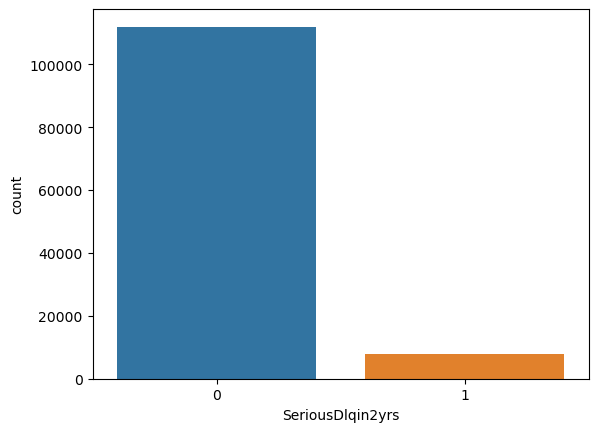

In [ ]:
sns.countplot(data=pool, x="SeriousDlqin2yrs", hue="SeriousDlqin2yrs", legend=False)

### Missing values

Before looking at shapes, we list every column that is incomplete on the pool, as a percentage of its 120,000 rows. The question is which gaps exist, and whether they are large enough to matter for the two models.

In [30]:
missings = pool.isnull().sum() * 100 / len(pool)
missings[missings > 0].sort_values(ascending=False)

MonthlyIncome         19.729167
NumberOfDependents     2.606667
dtype: float64

Monthly income is missing for 19.73 percent of the pool, and number of dependents for 2.61 percent. Every other column is complete. 

The income gap is the one that will matter again: it is large, and when we reach the debt ratio it turns out to be tied to the extreme values of that field.

### Age

Age is the most ordinary demographic in the file. The histogram shows the pool, with serious delinquency overlaid. We then count the two edges that fall outside the body of that chart: ages over 80, and ages under 18.

<Axes: xlabel='age', ylabel='Count'>

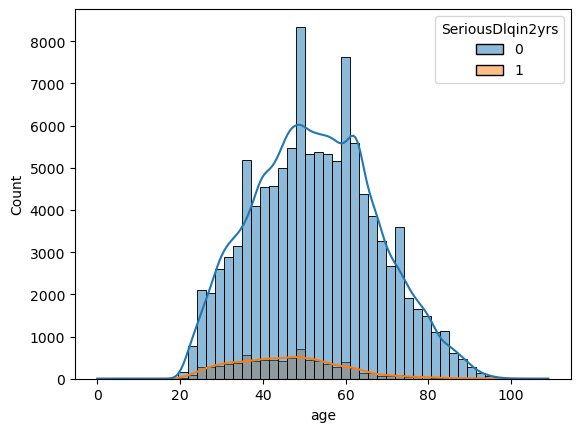

In [31]:
sns.histplot(data=pool, x="age", hue="SeriousDlqin2yrs", bins=50, kde=True)

In [302]:
print(pool[pool["age"] > 80].shape[0])
print(pool[pool["age"] > 80].shape[0] * 100 / len(pool))

3927
3.2725


In [306]:
print(pool[pool["age"] < 18].shape[0])
print(pool[pool["age"] < 18].shape[0] * 100 / len(pool))

1
0.0008333333333333334


The body of the distribution is a single mound centered at 52, from the early twenties through about 80. Serious delinquency follows that same mound, and it thins out among the older applicants. One row is under 18, which is 0.0008 percent of the pool, and the minimum in the summary is 0, so that row is a broken age. At the other end, 3,927 applicants are older than 80, which is 3.27 percent of the pool, and the oldest recorded age is 109. Preprocessing will set both of these edges to missing, and the models can treat the age on those rows as unknown.

### Revolving utilization of unsecured lines

`RevolvingUtilizationOfUnsecuredLines` is the revolving balance divided by the credit limit. On a usable credit file that ratio lives near the unit interval: near 0 when the lines are unused, near 1 when they are fully drawn, and only somewhat above 1 when the balance has passed the limit. The summary is on a different scale. The median on the pool is 0.15 and the 75th percentile is 0.56, while the mean is 6.13 and the maximum is 50,708. 

<Axes: xlabel='RevolvingUtilizationOfUnsecuredLines', ylabel='Count'>

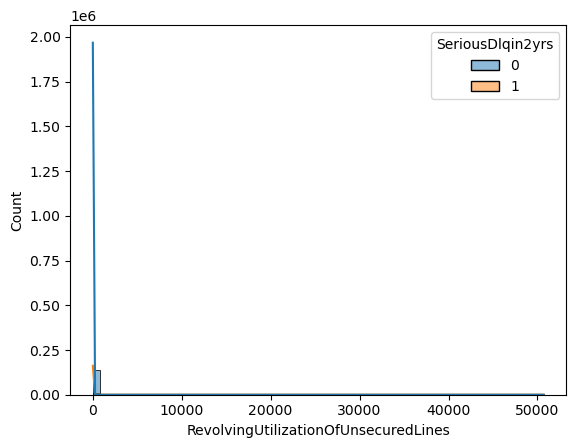

In [341]:
sns.histplot(data=df, x="RevolvingUtilizationOfUnsecuredLines", hue="SeriousDlqin2yrs", bins=60, kde=True)

In [324]:
print(pool[pool['RevolvingUtilizationOfUnsecuredLines'] > 13].shape[0] * 100 / len(pool))

0.15583333333333332


<Axes: xlabel='RevolvingUtilizationOfUnsecuredLines', ylabel='Count'>

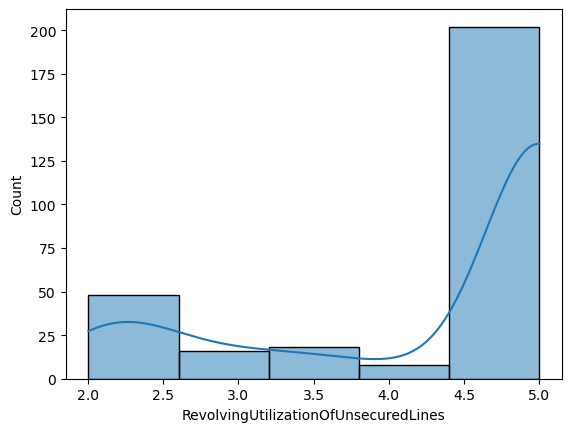

In [ ]:
mask = pool.copy()
mask['RevolvingUtilizationOfUnsecuredLines'] = pool['RevolvingUtilizationOfUnsecuredLines'].apply(lambda x: 5 if x > 5 else x)
mask = mask[mask['RevolvingUtilizationOfUnsecuredLines'] > 2]
sns.histplot(data=mask, x="RevolvingUtilizationOfUnsecuredLines", bins=5, kde=True)

The raw histogram collapses to a spike at zero. One extreme stretches the axis to about 50,000, and both classes are piled into that same spike. On the pool, values above 13 are 0.16 percent of rows, so the unreadable axis comes from a very small tail.

The last chart caps the field at 5 and keeps only rows above 2. That region is already far past ordinary use of a credit line. The bins between 2 and 5 are small. The tall bin at 5 is the cap itself: every row that originally sat above 5, piled onto a single point. The quartiles put the mass of the field well below 1, so the cap sits out in the extreme tail. Preprocessing will clip RevolvingUtilizationOfUnsecuredLines above 5.

### Times 30–59 days past due, and not worse

NumberOfTime30-59DaysPastDueNotWorse counts how often the applicant was 30 to 59 days past due without a worse delinquency. It should be a small integer, and for most people it should be zero. 

<Axes: xlabel='NumberOfTime30-59DaysPastDueNotWorse', ylabel='Count'>

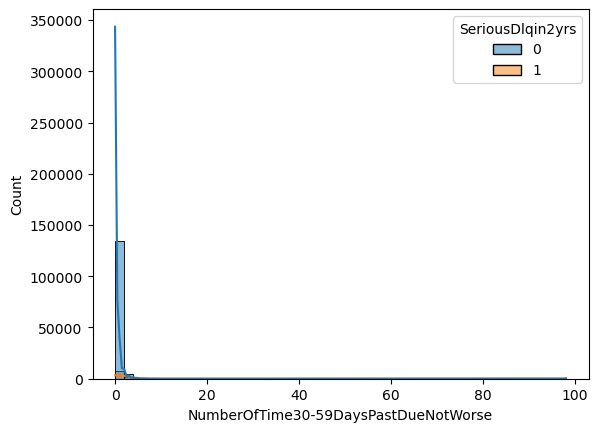

In [87]:
sns.histplot(data=df, x="NumberOfTime30-59DaysPastDueNotWorse", hue="SeriousDlqin2yrs", bins=50, kde=True)

In [122]:
print(pool[pool['NumberOfTime30-59DaysPastDueNotWorse'] > 9].shape[0] * 100 / len(pool))

0.185


<Axes: xlabel='NumberOfTime30-59DaysPastDueNotWorse', ylabel='Count'>

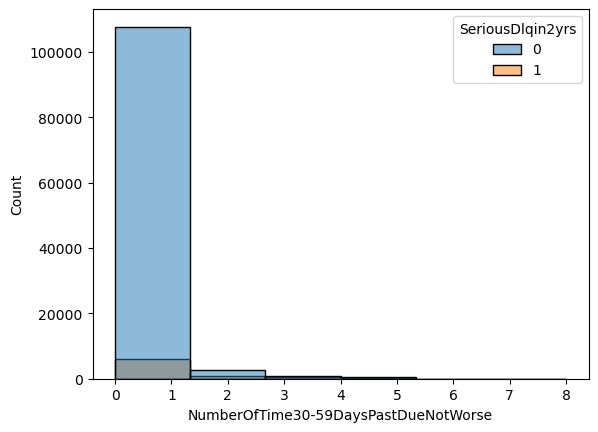

In [ ]:
mask = pool[pool['NumberOfTime30-59DaysPastDueNotWorse'] < 9]
sns.histplot(data=mask, x="NumberOfTime30-59DaysPastDueNotWorse", hue="SeriousDlqin2yrs", bins=6)

<Axes: xlabel='NumberOfTime30-59DaysPastDueNotWorse', ylabel='Count'>

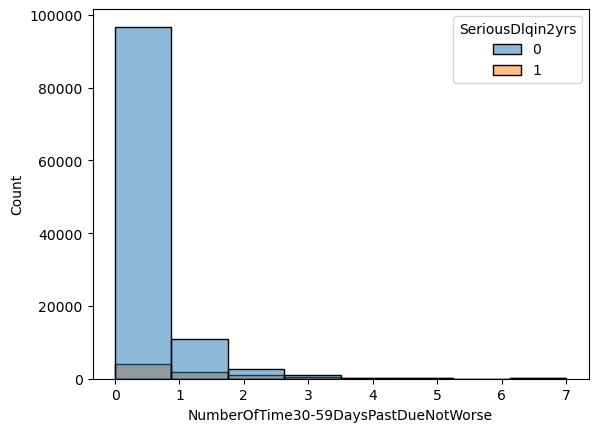

In [ ]:
mask = pool.copy()
mask["NumberOfTime30-59DaysPastDueNotWorse"] = mask["NumberOfTime30-59DaysPastDueNotWorse"].apply(lambda x:7 if x > 6 else x)
sns.histplot(data=mask, x="NumberOfTime30-59DaysPastDueNotWorse", hue="SeriousDlqin2yrs", bins=8)

On the full file the maximum of 98 stretches the axis, and almost every applicant falls into the first bin. On the pool, counts above 9 are 0.19 percent of rows. Restricting to counts below 9 shows the shape that matters: a large mass at zero, a steep drop through one, two, and three, and very little left by six, seven, or eight. Serious delinquency is a larger share of those higher counts than it is of the zero count, which is the association worth keeping.

The last chart places every value above 6 at 7. The new last bin is small beside the mass at zero, and the body of the variable is unchanged. Preprocessing will clip NumberOfTime30-59DaysPastDueNotWorse above 6.

### Debt ratio

`DebtRatio` is meant to be monthly debt payments divided by monthly income. A clean ratio would sit between zero and a small number above one. The summary is on a different scale: the median is 0.37 and the 75th percentile is 0.86, while the mean is 352 and the maximum is 329,664. 

<Axes: xlabel='DebtRatio', ylabel='Count'>

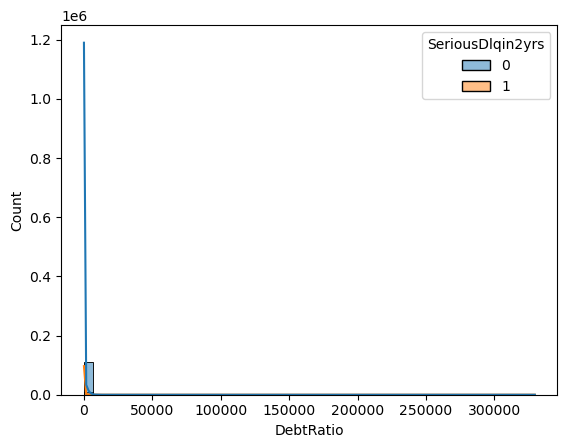

In [137]:
sns.histplot(data=pool, x="DebtRatio", hue="SeriousDlqin2yrs", bins=50, kde=True)

In [354]:
print(pool[pool["DebtRatio"] > 10].shape[0] * 100 / len(pool))

mask = (pool["DebtRatio"] > 10) & (
    (pool["MonthlyIncome"] < 100) | (pool["MonthlyIncome"].isna())
)

print(pool[mask].shape[0] * 100 / len(pool))

19.1825
19.114166666666666


<Axes: xlabel='DebtRatio', ylabel='Count'>

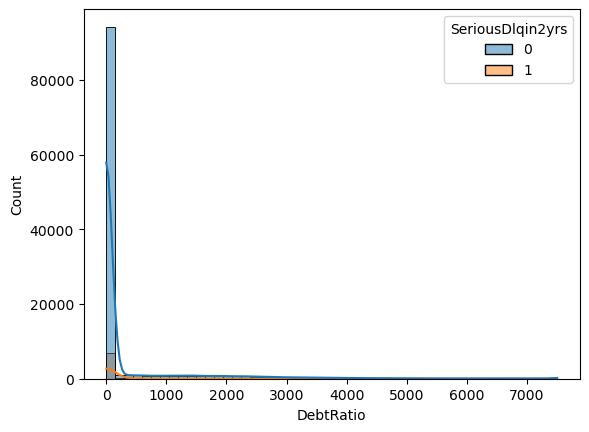

In [355]:
mask = pool.copy()
mask["DebtRatio"] = mask["DebtRatio"].apply(lambda x: 7500 if x > 7500 else x)
sns.histplot(data=mask, x="DebtRatio", hue="SeriousDlqin2yrs", bins=50, kde=True)

The two printed shares are almost the same number. A debt ratio above 10 covers 19.18 percent of the pool, and 19.11 percent of the pool has a debt ratio above 10 together with a monthly income below 100 or a missing income. The extreme ratios sit on broken incomes. The natural reading is that DebtRatio was filled in automatically from MonthlyIncome, so a missing or near-zero income is enough to blow the ratio up.

A proper repair of the ratio would clean and impute monthly income first. In the decisions at the end of the notebook, those missing incomes are left missing, because CatBoost and TabFM accept a missing value as an input. A very large debt ratio in this file is a trace of a missing or tiny income. After testing clipping at 7500, it was decided to implement it for preprocessing.

### Monthly income

`MonthlyIncome` is the field with the largest gap, 19.73 percent of the pool, and it is also heavily skewed where it is filled in. The median is 5,390 and the 75th percentile is 8,238, against a maximum of about 3 million.

<Axes: xlabel='MonthlyIncome', ylabel='Count'>

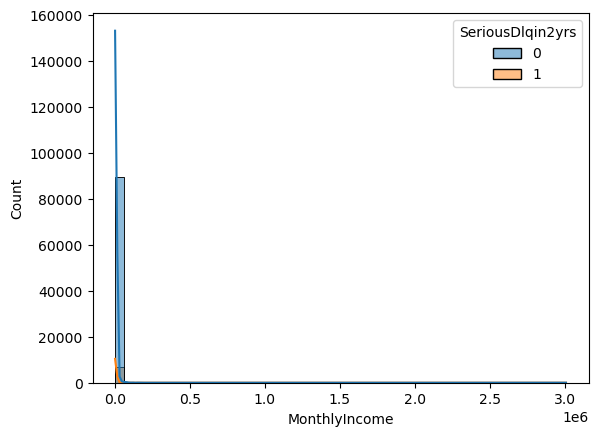

In [165]:
sns.histplot(data=pool, x="MonthlyIncome", hue="SeriousDlqin2yrs", bins=50, kde=True)

<Axes: xlabel='MonthlyIncome', ylabel='Count'>

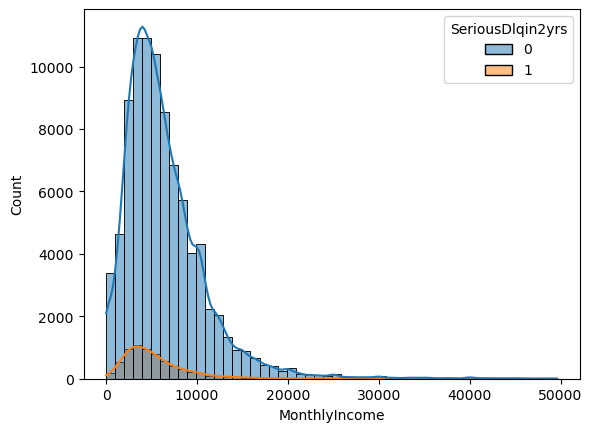

In [ ]:
pool[pool["MonthlyIncome"] > 50000].shape[0] * 100 / len(pool)

mask = pool[pool["MonthlyIncome"] < 50000]
sns.histplot(data=mask, x="MonthlyIncome", hue="SeriousDlqin2yrs", bins=50, kde=True)

<Axes: xlabel='MonthlyIncome', ylabel='Count'>

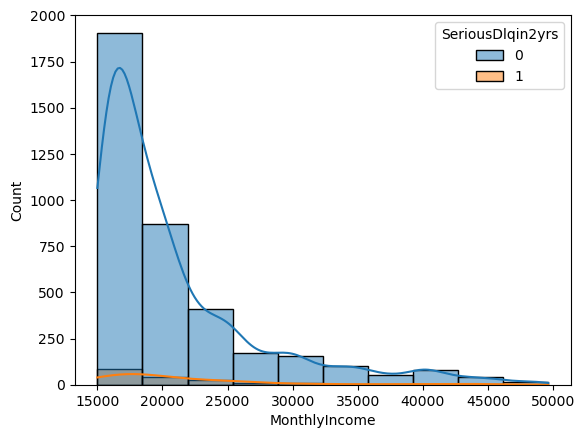

In [ ]:
mask = pool[(pool["MonthlyIncome"] > 20000) & (pool["MonthlyIncome"] < 50000)]

sns.histplot(data=mask, x="MonthlyIncome", hue="SeriousDlqin2yrs", bins=10, kde=True)

<Axes: xlabel='MonthlyIncome', ylabel='Count'>

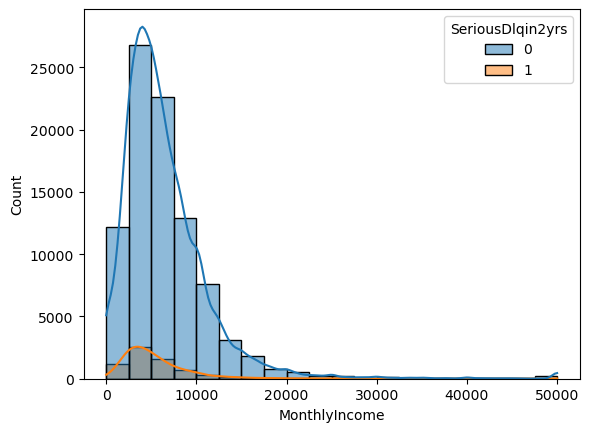

In [183]:
mask = pool.copy()

mask["MonthlyIncome"] = mask["MonthlyIncome"].apply(lambda x: 50000 if x > 50000 else x)

sns.histplot(data=mask, x="MonthlyIncome", hue="SeriousDlqin2yrs", bins=20, kde=True)

The raw histogram is a spike at the origin, because a few incomes in the millions set the axis and the rest of the sample has no room. Restricting to incomes below 50,000 reveals one smooth, right-skewed mound, centered around a few thousand dollars. Both classes follow that shape. The band from 20,000 to 50,000 is the far shoulder of the same mound, and it declines steadily all the way toward 50,000.

The last chart caps the filled-in values at 50,000. A small pile of rows sits on the right edge, and the mound itself is intact. The cap is there so the body of the chart can be read. In preprocessing, monthly income keeps its long tail, and the 19.73 percent of values that are missing stay missing.

### Open credit lines and loans

`NumberOfOpenCreditLinesAndLoans` is a count of open credit lines and loans. The histogram is the pool, with the two classes overlaid. We are checking whether this count has the same kind of broken tail as the delinquency fields, or whether it is already on a readable scale.

<Axes: xlabel='NumberOfOpenCreditLinesAndLoans', ylabel='Count'>

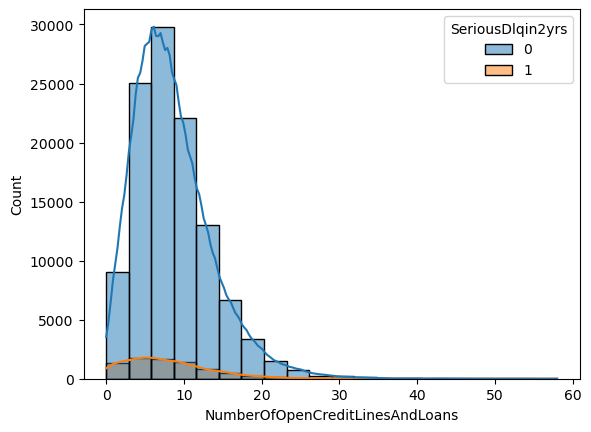

In [184]:
sns.histplot(data=pool, x="NumberOfOpenCreditLinesAndLoans", hue="SeriousDlqin2yrs", bins=20, kde=True)

The distribution has one mode, centered near eight open lines, with a tail that thins out past about twenty and a maximum of 58. Serious delinquency follows the same curve at a much smaller volume. The tail is a thin continuation of that same curve. This variable is left as recorded.

### Times 90 days late

`NumberOfTimes90DaysLate` is the delinquency count closest to the target, since the label itself is a 90-day event over the next two years. Most applicants should be at zero. The summary maximum is again 98, so the first chart of the whole pool is likely to collapse, and the next charts restrict the view: first to applicants with at least one event, then to the band above 4 and below 90, where a real tail would have to live if it existed.

<Axes: xlabel='NumberOfTimes90DaysLate', ylabel='Count'>

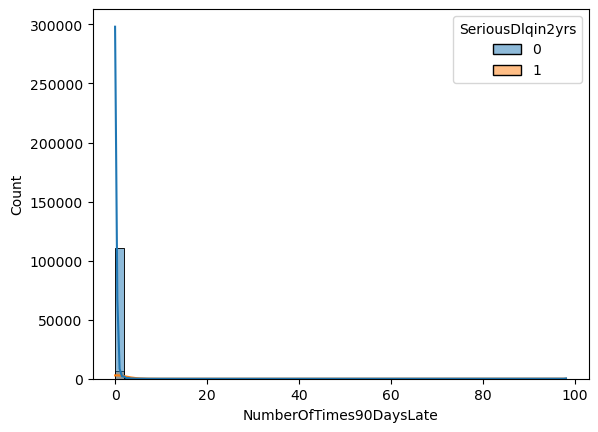

In [186]:
sns.histplot(data=pool, x="NumberOfTimes90DaysLate", hue="SeriousDlqin2yrs", bins=50, kde=True)

5.588333333333333


<Axes: xlabel='NumberOfTimes90DaysLate', ylabel='Count'>

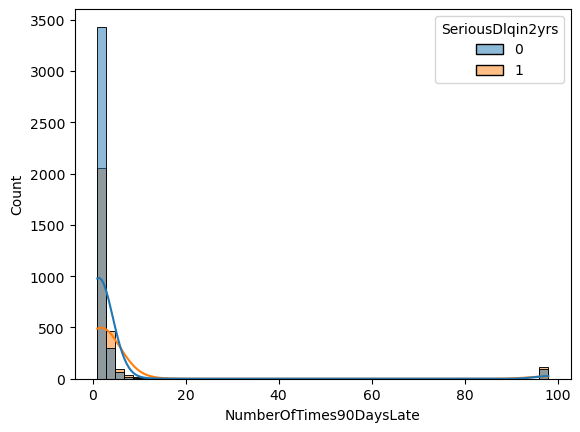

In [191]:
print(pool[pool["NumberOfTimes90DaysLate"] > 0].shape[0] * 100 / len(pool))

mask = pool[pool["NumberOfTimes90DaysLate"] > 0]
sns.histplot(data=mask, x="NumberOfTimes90DaysLate", hue="SeriousDlqin2yrs", bins=50, kde=True)

<Axes: xlabel='NumberOfTimes90DaysLate', ylabel='Count'>

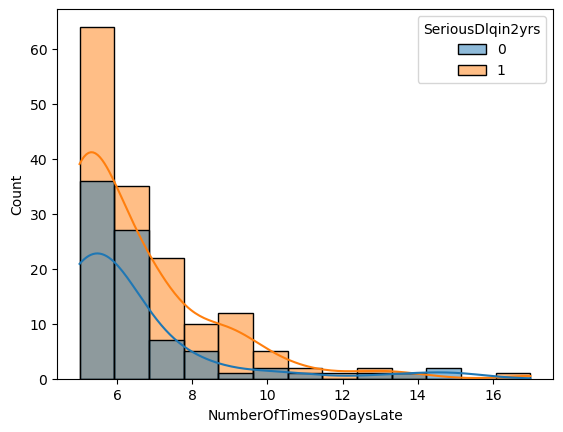

In [214]:
mask = pool[(pool["NumberOfTimes90DaysLate"] > 4) & (pool["NumberOfTimes90DaysLate"] < 90)]
sns.histplot(data=mask, x="NumberOfTimes90DaysLate", hue="SeriousDlqin2yrs", bins=13, kde=True)

On the whole pool the chart is a spike at zero, as expected with a maximum of 98. Among the 5.59 percent of applicants who have at least one 90-day event, the counts fall quickly and a separate pile sits near 100. That pile is the same kind of ceiling seen on the other past-due fields.

The chart restricted to counts above 4 and below 90 drops that ceiling. What remains is a short, thin tail. By the high teens almost nobody is left. Serious delinquency accounts for a large share of these rows, which fits the meaning of the field, because a history of 90-day lates is close to the event the label records. Seventeen is a point past the end of that tail, and the next chart tries a cap there.

<Axes: xlabel='NumberOfTimes90DaysLate', ylabel='Count'>

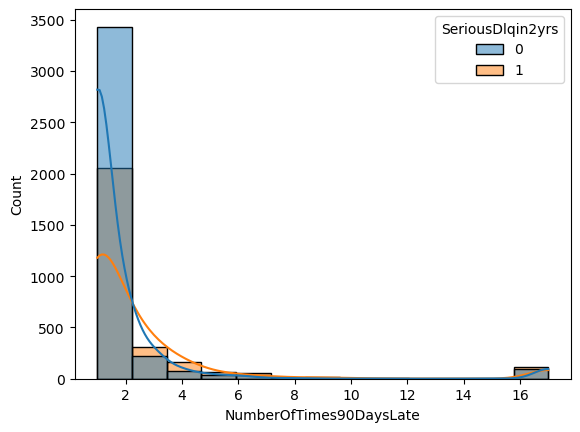

In [224]:
mask = pool.copy()
mask["NumberOfTimes90DaysLate"] = mask["NumberOfTimes90DaysLate"].apply(lambda x: 17 if x > 17 else x)
mask = mask[mask["NumberOfTimes90DaysLate"] > 0]
sns.histplot(data=mask, x="NumberOfTimes90DaysLate", hue="SeriousDlqin2yrs", bins=13, kde=True)

The trial in the last chart caps every count above 17 at 17, and it drops the zeros so the tail is visible. The decline through the small integers stays in place. The bin at 17 collects what used to be the sparse tail together with the pile that sat near 98. That is a small share of applicants, and it is far past the point where the band from 4 to 90 had already run out of rows. Clipping NumberOfTimes90DaysLate above 17 is the rule we keep.

### Real-estate loans or lines

`NumberRealEstateLoansOrLines` counts mortgage and real-estate lines. The first chart is the whole pool. We then measure how many applicants have more than five, and we redraw just that upper piece, to see whether the right-hand side is a smooth tail or a broken code.

<Axes: xlabel='NumberRealEstateLoansOrLines', ylabel='Count'>

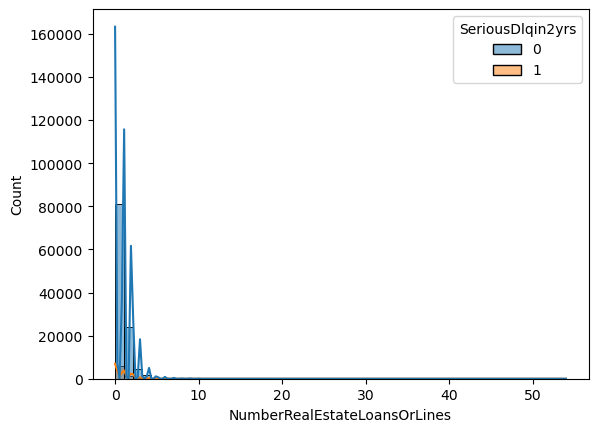

In [230]:
sns.histplot(data=pool, x="NumberRealEstateLoansOrLines", hue="SeriousDlqin2yrs", bins=50, kde=True)

0.5216666666666666


<Axes: xlabel='NumberRealEstateLoansOrLines', ylabel='Count'>

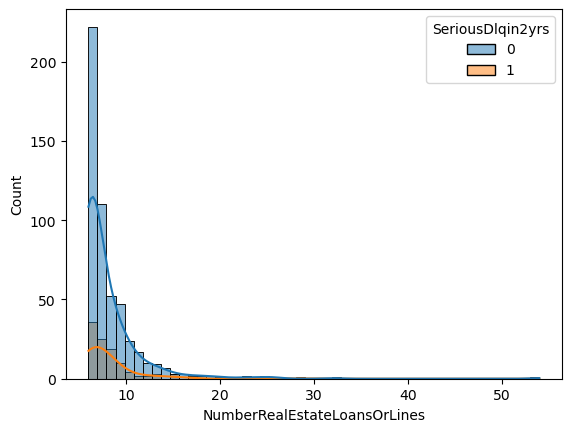

In [251]:
print(pool[pool["NumberRealEstateLoansOrLines"] > 5].shape[0] * 100 / len(pool))

mask = pool[pool["NumberRealEstateLoansOrLines"] > 5]
sns.histplot(data=mask, x="NumberRealEstateLoansOrLines", hue="SeriousDlqin2yrs", bins=50, kde=True)

In [ ]:
pool["NumberRealEstateLoansOrLines"]

NumberRealEstateLoansOrLines
0     44900
1     41928
2     25254
3      5011
4      1721
5       560
6       258
7       135
8        71
9        57
10       28
11       19
13       12
12       12
14        7
15        6
17        3
16        3
25        3
19        2
23        2
18        2
20        1
54        1
26        1
21        1
32        1
29        1
Name: count, dtype: int64

The histogram is dominated by zero, one, and two real-estate loans, and the axis only has to reach 54, so the whole shape is visible. Applicants with more than five real-estate loans are 0.52 percent of the pool. The zoomed chart declines smoothly from there and is essentially finished by about twenty, with a single extreme at the maximum of 54. The tail still reads as a count of loans. This field stays as recorded.

### Times 60–89 days past due, and not worse

`NumberOfTime60-89DaysPastDueNotWorse` is the middle delinquency count. As with the other two past-due fields, the summary maximum is 98, so the first chart of the whole pool will be dominated by the zero count. The next chart keeps only counts above 4, which is where a long tail or a ceiling would show, and the last cell lists the values above 80.

<Axes: xlabel='NumberOfTime60-89DaysPastDueNotWorse', ylabel='Count'>

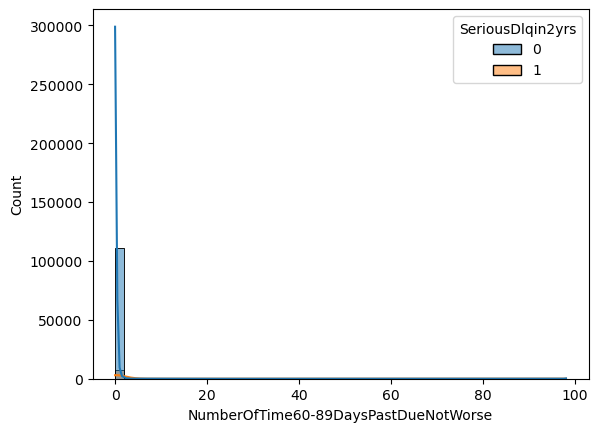

In [257]:
sns.histplot(data=pool, x="NumberOfTime60-89DaysPastDueNotWorse", hue="SeriousDlqin2yrs", bins=50, kde=True)

<Axes: xlabel='NumberOfTime60-89DaysPastDueNotWorse', ylabel='Count'>

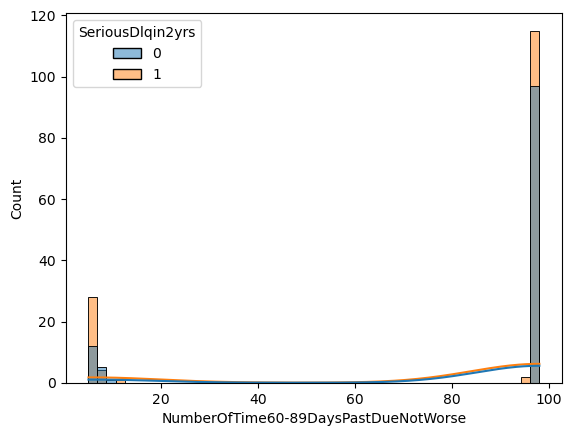

In [267]:
pool[pool["NumberOfTime60-89DaysPastDueNotWorse"] > 4].shape[0] * 100 / len(pool)

mask = pool[pool["NumberOfTime60-89DaysPastDueNotWorse"] > 4]
sns.histplot(data=mask, x="NumberOfTime60-89DaysPastDueNotWorse", hue="SeriousDlqin2yrs", bins=50, kde=True)

In [271]:
pool[pool["NumberOfTime60-89DaysPastDueNotWorse"] > 80]["NumberOfTime60-89DaysPastDueNotWorse"].value_counts()

NumberOfTime60-89DaysPastDueNotWorse
98    212
96      2
Name: count, dtype: int64

The restricted chart has almost no one in the middle of the range. What remains above 80 takes only two values: 212 applicants are recorded as 98, and 2 are recorded as 96. The upper end looks as if it has already been winsorized, with 98 used as the cap. This field is left as recorded.

### Number of dependents

`NumberOfDependents` is the second incomplete field: 2.61 percent of the pool is missing. Where it is filled in, we look at the whole distribution and then at how many applicants report more than five dependents. The question is whether the right tail is a real, thin count or another sentinel value.

<Axes: xlabel='NumberOfDependents', ylabel='Count'>

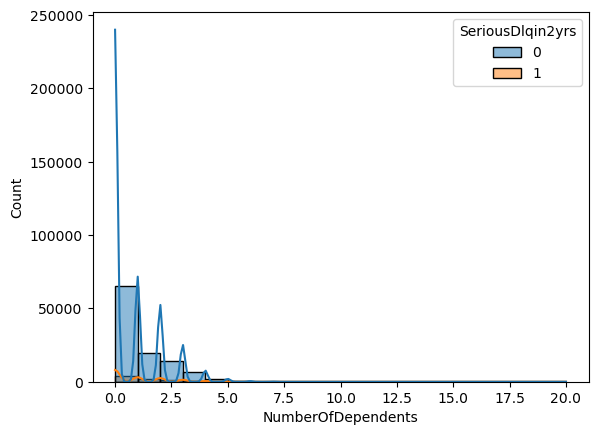

In [279]:
sns.histplot(data=pool, x="NumberOfDependents", hue="SeriousDlqin2yrs", bins=20, kde=True)

In [338]:
print(pool[pool["NumberOfDependents"] > 5].shape[0] * 100 / len(pool))


0.16583333333333333


Where the field is filled in, the counts form a short staircase. A large mass sits at zero dependents, then at one, two, and three, and very little remains beyond that. Serious delinquency follows the same steps. The maximum in the summary is 20, and more than five dependents is 0.17 percent of the pool. The upper end thins out smoothly, with none of the point mass at 96 and 98 that showed up on the past-due fields. This field is left as recorded, and its missing values stay missing.

### Preprocessing decisions

The rules for preprocessing are these.

- Missing values are left as missing. `MonthlyIncome` is missing for 19.73 percent of the pool and `NumberOfDependents` for 2.61 percent, and no other column has gaps. Both models support missing values, so neither field is imputed.
- Ages under 18 and over 80 are set to missing. There is a single age under 18, and 3,927 applicants, 3.27 percent of the pool, are older than 80, out to a maximum of 109.
- `RevolvingUtilizationOfUnsecuredLines` is clipped above 5. Ordinary values sit well below 1, values above 13 are 0.16 percent of the pool, and the raw maximum of 50,708 is what makes the unclipped histogram unreadable.
- `NumberOfTimes90DaysLate` is clipped above 17. Past that point the genuine tail has already run out, and what remains is the ceiling near 98.
- `NumberOfTime30-59DaysPastDueNotWorse` is clipped above 6. Counts above 9 are 0.19 percent of the pool, and below 9 the histogram is already down to a trace by 6.
- `DebtRatio` is clipped above 7500.

The other fields stay as recorded. Open credit lines are a single readable mode around eight. Real-estate loans are mostly zero, one, or two, with a thin tail above five that is 0.52 percent of the pool. The 60–89 day count is already capped at 98. Monthly income stays skewed, and its missing values stay missing.